In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 12 - Higher education: attainment, fields (STEM), gender, doctorates, age
Eurostat education statistics (UOE data collection, EU Labour Force Survey). STEM = natural sciences, mathematics & statistics (F05), ICT (F06), engineering, manufacturing & construction (F07). Graduate counts are degrees, not people: a student with a bachelor and a master counts twice, and countries differ in cycle structure.

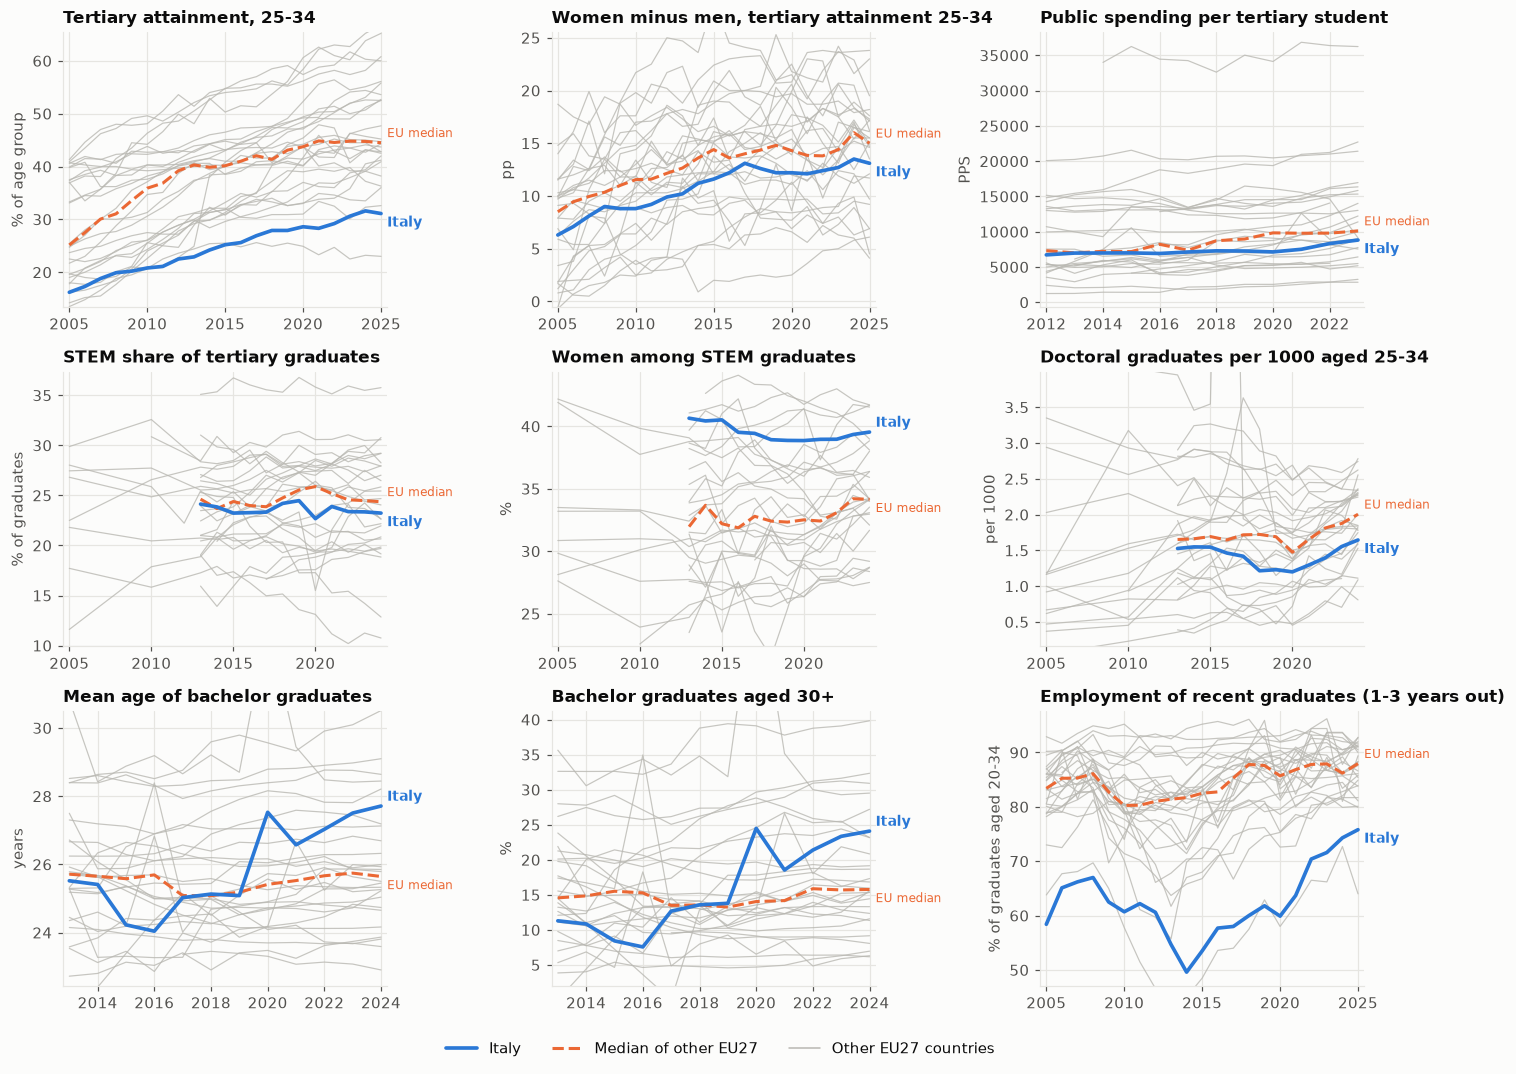

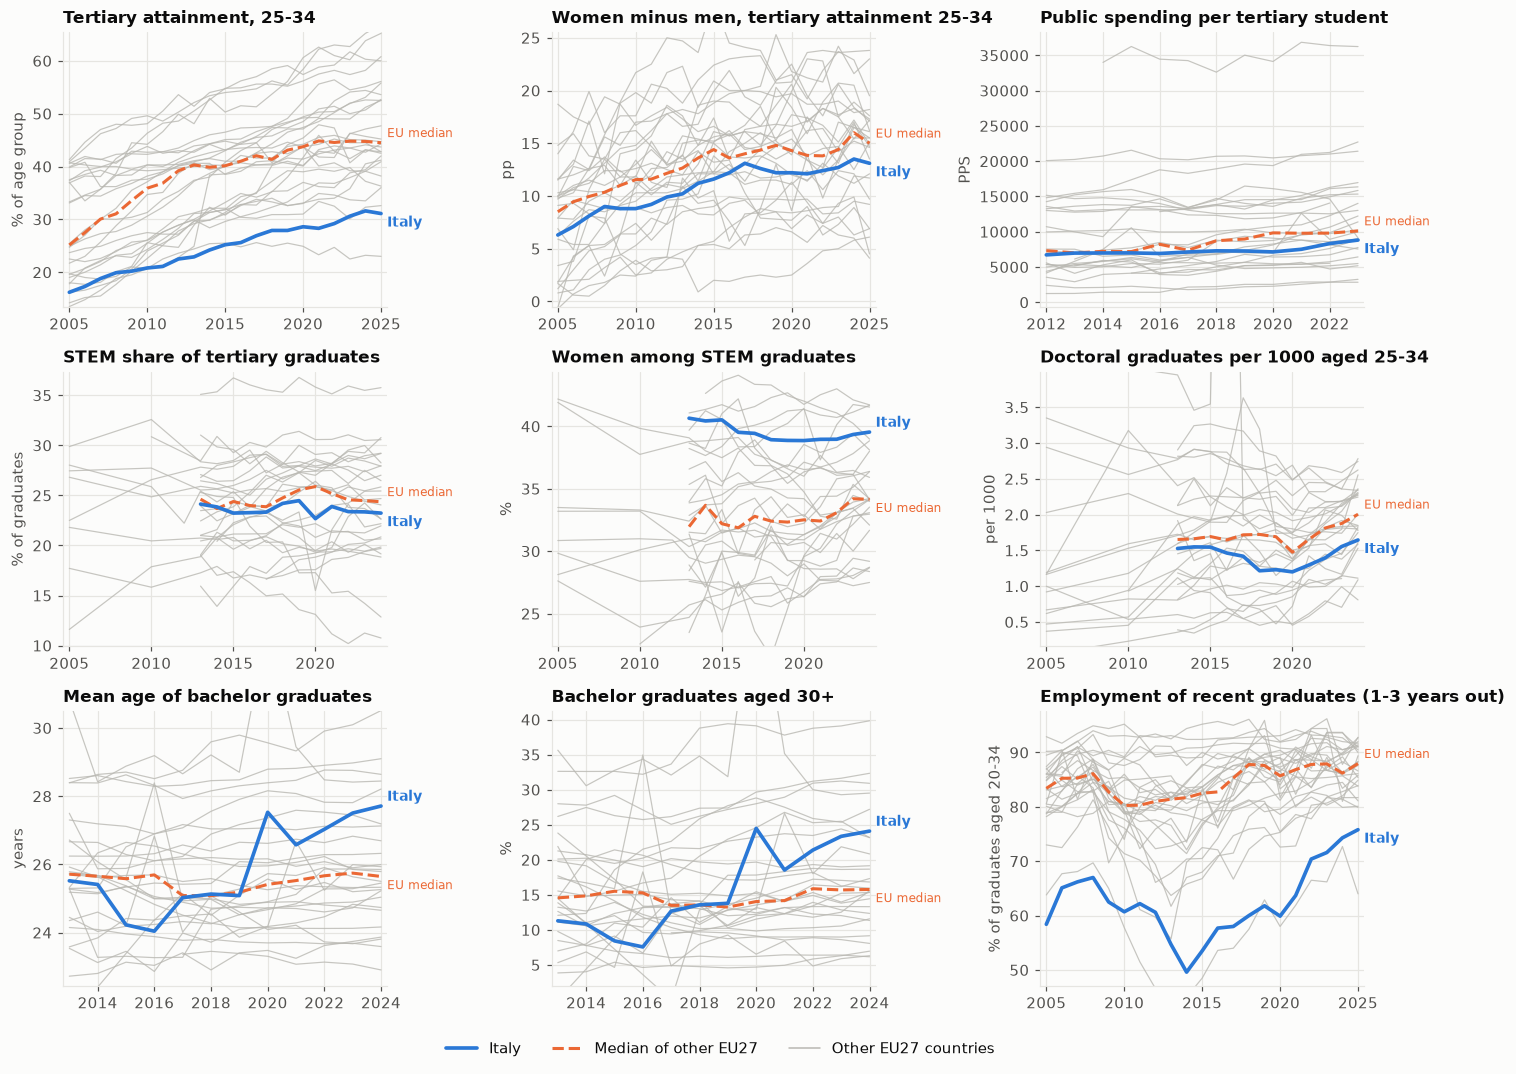

In [2]:
gender_gap = wide(panel, "tertiary_attainment_25_34_female") - wide(panel, "tertiary_attainment_25_34_male")
items = [
    (wide(panel, "tertiary_attainment_25_34"), "Tertiary attainment, 25-34", "% of age group"),
    (gender_gap, "Women minus men, tertiary attainment 25-34", "pp"),
    (wide(panel, "tertiary_spend_per_student_pps"), "Public spending per tertiary student", "PPS"),
    (wide(panel, "stem_share_grads_pct"), "STEM share of tertiary graduates", "% of graduates"),
    (wide(panel, "women_share_stem_grads_pct"), "Women among STEM graduates", "%"),
    (wide(panel, "phd_grads_per_1000_pop_25_34"), "Doctoral graduates per 1000 aged 25-34", "per 1000"),
    (wide(panel, "mean_age_grads_bachelor"), "Mean age of bachelor graduates", "years"),
    (wide(panel, "bachelor_grads_30plus_pct"), "Bachelor graduates aged 30+", "%"),
    (wide(panel, "recent_grads_employment_rate"), "Employment of recent graduates (1-3 years out)", "% of graduates aged 20-34"),
]
small_multiples_wide(items, ncols=3, name="12_higher_ed_overview")

Field analysis year: 2024


,Italy,Median of other EU27,Germany
iscedf13,,,
Generic programmes,0.0,0.0,0.0
ICT,1.6,5.7,6.2
Agriculture & veterinary,1.8,1.8,1.6
Services,4.1,4.9,3.3
Education,6.1,9.6,10.6
"Natural sciences, maths & statistics",7.9,5.0,8.2
Health & welfare,12.2,15.0,8.3
"Engineering, manufacturing & construction",13.7,12.0,21.3
Social sciences & journalism,15.2,9.9,7.4


STEM share (F05+F06+F07): {'Italy': np.float64(23.2), 'median others': np.float64(24.4), 'Germany': np.float64(35.8)}


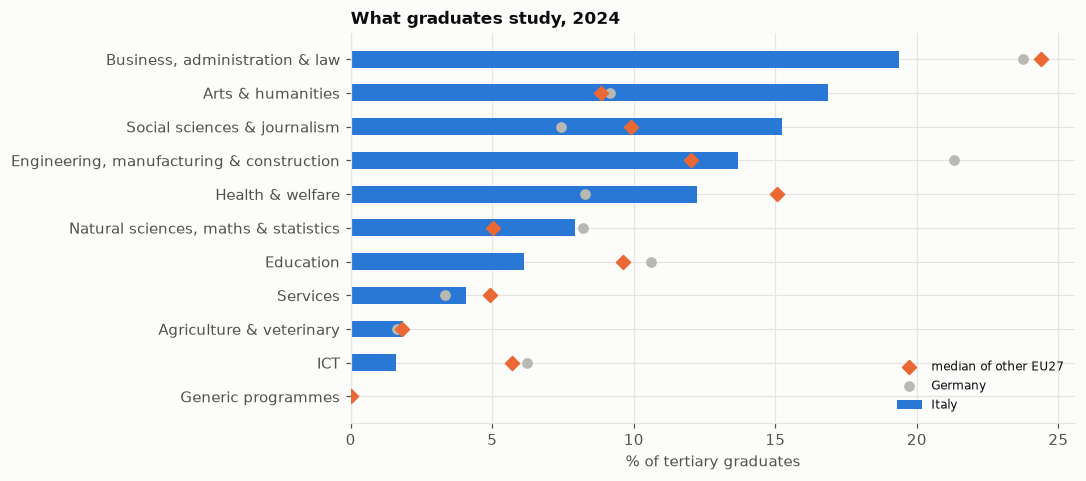

In [3]:
he = load_highered(); Y = broad_year(he, "he_grads_field"); print("Field analysis year:", Y)
sh = field_shares(he, "he_grads_field", "ED5-8", "T", Y); eu = [c for c in sh.index if c in EU27_ISO3]
tab = pd.DataFrame({"Italy": sh.loc[ITALY], "Median of other EU27": sh.loc[[c for c in eu if c != ITALY]].median(), "Germany": sh.loc["DEU"]}).rename(index=FIELD_LABELS).sort_values("Italy")
fig, ax = plt.subplots(figsize=(8.5, 4.6)); yy = np.arange(len(tab))
ax.barh(yy, tab["Italy"], color=ITALY_C, height=0.5, label="Italy", zorder=2)
ax.scatter(tab["Median of other EU27"], yy, color=EU_C, s=42, marker="D", zorder=3, label="median of other EU27")
ax.scatter(tab["Germany"], yy, color=PEER_C, s=36, zorder=2, label="Germany")
ax.set_yticks(yy, tab.index); ax.set_xlabel("% of tertiary graduates"); ax.set_title(f"What graduates study, {Y}"); ax.legend(fontsize=8, loc="lower right"); save(fig, "12_fields")
display(tab.round(1)); print("STEM share (F05+F06+F07):", {k: round(v, 1) for k, v in {"Italy": sh.loc[ITALY, STEM_FIELDS].sum(), "median others": sh.loc[[c for c in eu if c != ITALY], STEM_FIELDS].sum(axis=1).median(), "Germany": sh.loc["DEU", STEM_FIELDS].sum()}.items()})

Italy  \
level                                     all tertiary graduates   
field                                                              
Agriculture & veterinary                                    49.0   
All fields                                                  58.0   
Arts & humanities                                           71.0   
Business, administration & law                              51.0   
Education                                                   91.0   
Engineering, manufacturing & construction                   31.0   
Generic programmes                                           NaN   
Health & welfare                                            67.0   
ICT                                                         18.0   
Natural sciences, maths & statistics                        58.0   
Services                                                    39.0   
Social sciences & journalism                                67.0   

                                                              \
level                                     doctoral graduates   
field                                                          
Agriculture & veterinary                                55.0   
All fields                                              48.0   
Arts & humanities                                       57.0   
Business, administration & law                          52.0   
Education                                               76.0   
Engineering, manufacturing & construction               33.0   
Generic programmes                                       NaN   
Health & welfare                                        57.0   
ICT                                                     21.0   
Natural sciences, maths & statistics                    51.0   
Services                                                21.0   
Social sciences & journalism                            56.0   

                                            median of other EU27  \
level                                     all tertiary graduates   
field                                                              
Agriculture & veterinary                                    58.0   
All fields                                                  60.0   
Arts & humanities                                           68.0   
Business, administration & law                              60.0   
Education                                                   82.0   
Engineering, manufacturing & construction                   29.0   
Generic programmes                                          89.0   
Health & welfare                                            77.0   
ICT                                                         21.0   
Natural sciences, maths & statistics                        58.0   
Services                                                    46.0   
Social sciences & journalism                                70.0   

                                                              
level                                     doctoral graduates  
field                                                         
Agriculture & veterinary                                59.0  
All fields                                              51.0  
Arts & humanities                                       55.0  
Business, administration & law                          48.0  
Education                                               71.0  
Engineering, manufacturing & construction               34.0  
Generic programmes                                       NaN  
Health & welfare                                        64.0  
ICT                                                     30.0  
Natural sciences, maths & statistics                    49.0  
Services                                                40.0  
Social sciences & journalism                            57.0

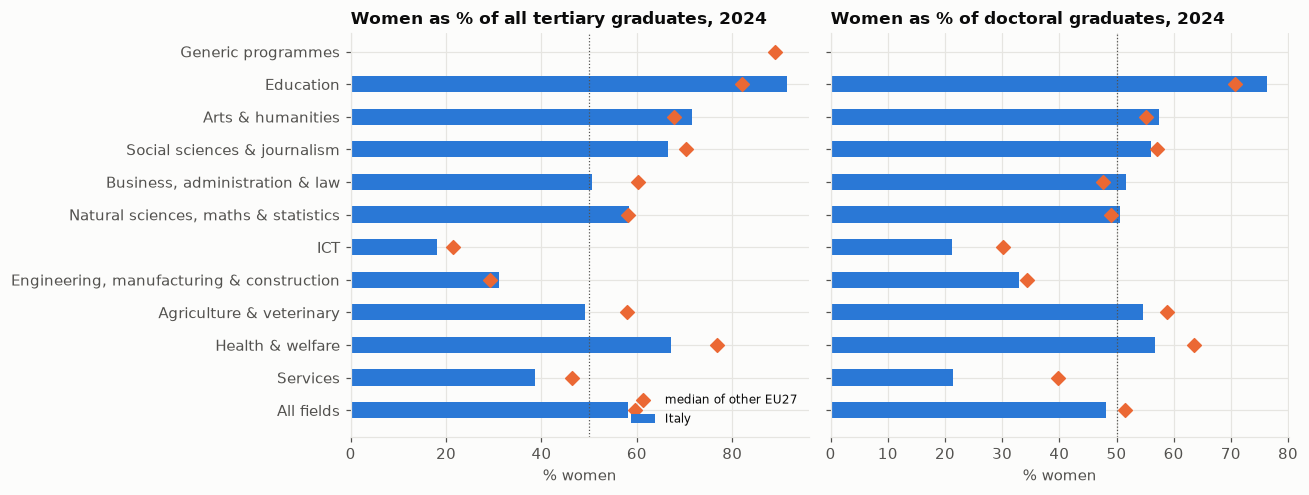

In [4]:
# Women's share of graduates by field, and doctoral level
wf = women_share_by_field(he, "he_grads_field", "ED5-8", Y); wd = women_share_by_field(he, "he_grads_field", "ED8", Y)
rows = []
for lab, w in [("all tertiary graduates", wf), ("doctoral graduates", wd)]:
    eu = [c for c in w.index if c in EU27_ISO3 and c != ITALY]
    rows.append(pd.DataFrame({"Italy": w.loc[ITALY], "median of other EU27": w.loc[eu].median()}).rename(index={**FIELD_LABELS, "TOTAL": "All fields"}).assign(level=lab))
t = pd.concat(rows).reset_index(names="field")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (lab, g) in zip(axes, t.groupby("level", sort=False)):
    g = g.set_index("field").loc[[*FIELD_LABELS.values(), "All fields"]]; yy = np.arange(len(g))
    ax.barh(yy, g["Italy"], color=ITALY_C, height=0.5, zorder=2, label="Italy"); ax.scatter(g["median of other EU27"], yy, color=EU_C, marker="D", s=40, zorder=3, label="median of other EU27")
    ax.axvline(50, color=INK2, lw=0.8, ls=":"); ax.set_yticks(yy, g.index); ax.set_title(f"Women as % of {lab}, {Y}"); ax.set_xlabel("% women")
axes[0].invert_yaxis(); axes[0].legend(fontsize=8, loc="lower right"); fig.tight_layout(); save(fig, "12_women_by_field")
display(t.pivot(index="field", columns="level", values=["Italy", "median of other EU27"]).round(0))

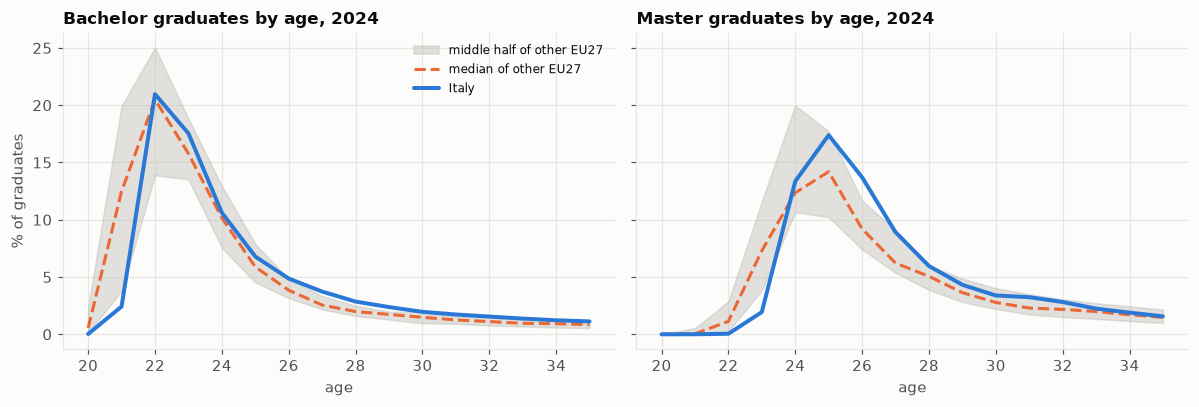

In [5]:
# Age at graduation: share of bachelor and master graduates by single year of age
ages = [f"Y{a}" for a in range(20, 36)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (lvl, nm) in zip(axes, [("ED6", "Bachelor"), ("ED7", "Master")]):
    ya = broad_year(he[he.isced11 == lvl], "he_grads_age")
    p = age_profile(he, lvl, ya, ages); oth = p.loc[[c for c in p.index if c in EU27_ISO3 and c != ITALY]]
    x = [int(a[1:]) for a in ages]
    ax.fill_between(x, oth.quantile(0.25), oth.quantile(0.75), color=PEER_C, alpha=0.4, label="middle half of other EU27")
    ax.plot(x, oth.median(), color=EU_C, ls="--", lw=2, label="median of other EU27"); ax.plot(x, p.loc[ITALY], color=ITALY_C, lw=2.6, label="Italy")
    ax.set_title(f"{nm} graduates by age, {ya}"); ax.set_xlabel("age")
axes[0].set_ylabel("% of graduates"); axes[0].legend(fontsize=8); fig.tight_layout(); save(fig, "12_graduation_age")

In [6]:
# Latest values and rank among the EU27 for all higher-education indicators
names = ["tertiary_attainment_25_34", "tertiary_attainment_25_34_female", "tertiary_attainment_25_34_male", "tertiary_attainment_25_64", "tertiary_spend_per_student_pps",
         "grads_per_1000_pop_20_29", "stem_grads_per_1000_pop_20_29", "stem_share_grads_pct", "stem_share_grads_female_pct", "stem_share_grads_male_pct", "women_share_stem_grads_pct",
         "women_share_ict_grads_pct", "ict_share_grads_pct", "women_share_grads_pct", "phd_grads_per_1000_pop_25_34", "phd_women_share_pct", "phd_stem_share_pct",
         "mean_age_grads_bachelor", "mean_age_grads_master", "mean_age_grads_phd", "bachelor_grads_30plus_pct", "recent_grads_employment_rate", "recent_grads_employment_rate_female",
         "recent_secondary_grads_employment_rate"]
rows = {}
for n in names:
    w = wide(panel, n); y = int(w[ITALY].dropna().index.max()); y = min(y, 2024)
    rows[n] = {"year": y, "Italy": round(w.loc[y, ITALY], 1), "median others": round(eu_median_ex_italy(w).loc[y], 1), "rank (1=highest)": "%d/%d" % italy_rank(w, y)}
display(pd.DataFrame(rows).T)

,year,Italy,median others,rank (1=highest)
tertiary_attainment_25_34,2024,31.6,44.8,26/27
tertiary_attainment_25_34_female,2024,38.5,55.2,25/27
tertiary_attainment_25_34_male,2024,25.0,36.8,26/27
tertiary_attainment_25_64,2024,22.3,39.8,26/27
tertiary_spend_per_student_pps,2023,8817.1,10109.2,18/25
grads_per_1000_pop_20_29,2024,91.2,82.3,8/27
stem_grads_per_1000_pop_20_29,2024,21.2,19.5,13/27
stem_share_grads_pct,2024,23.2,24.4,15/27
stem_share_grads_female_pct,2024,15.8,14.3,12/27
stem_share_grads_male_pct,2024,33.5,38.5,21/27


## Takeaways (Eurostat; 2024 unless stated; median = other EU27 members)
- **Attainment is the gap, not graduate output.** 31.6% of 25-34 year-olds hold a tertiary degree (median 44.8%; 26th of 27); women 38.5% (median 55.2%), men 25.0% (median 36.8%). Italian women out-attain men by 13.5 pp, but both are far below peers. Public spending per tertiary student is 8,817 PPS (2023) vs 10,109 (18th of 25).
- **Degree counts look high, which reflects the 3+2 structure:** 91.2 graduates per 1000 people aged 20-29 (median 82.3; 8th) count degrees, not people (bachelor and master both count).
- **STEM is average in size, different in mix.** STEM is 23.2% of graduates (median 24.4%; Germany 35.8%), but ICT is only 1.6% (median 5.7%, last of 27) while natural sciences are 7.9% (median 5.0%) and engineering 13.7% (median 12.0%). Arts & humanities (16.9% vs 8.9%) and social sciences (15.2% vs 9.9%) are over-represented; business (19.4% vs 24.4%), education (6.1% vs 9.6%) and health (12.2% vs 15.0%) under-represented.
- **Gender and STEM.** Women are 58.1% of graduates (median 59.6%) but 39.5% of STEM graduates (median 34.2%; 4th highest), driven by natural sciences (58% women) and engineering (31%); in ICT they are 18% (median 21.5%). 15.8% of women graduates and 33.5% of men graduates study STEM (medians 14.3% and 38.5%).
- **Doctorates.** 1.6 doctoral graduates per 1000 aged 25-34 (median 2.0; 20th of 26); women are 48.1% of PhDs (median 51.5%); 55.3% of PhDs are in STEM (median 42.0%; 4th); the mean age at PhD is 32.4 (median 35.6).
- **Age.** Bachelor graduates are 27.7 on average (median 25.6) and 24.1% are 30 or older (median 15.8%, 6th highest); few Italians graduate at 20-21 and more do so in their late twenties. Master graduates average 29.8 (median 28.8).
- **Labour-market return.** 74.3% of recent graduates (1-3 years out, 20-34) are employed (median 86.2%; women 72.7% vs 84.8%), against 59.3% for recent upper-secondary graduates (median 76.0%). The gap to the EU is large for both groups: weaker demand for young workers matters as much as the skills mix.
- Not covered: first-generation or socio-economic background, field-level earnings, and doctoral stock (UK, US, Japan comparisons would need OECD Education at a Glance).

## Adult skills (PIAAC, 2023 and change since 2012)
OECD Survey of Adult Skills, adults aged 16-65. 19 EU members took part (Belgium and the UK only as regions, so they are absent). 2012 levels are the 2023 level minus the OECD's reported change. Scores are on a 0-500 scale.

,Italy,median others,rank (1=highest)
literacy,245.0,254.5,16/19
numeracy,244.0,262.0,17/19
adaptive problem solving,231.0,248.5,17/19
% at level 1 or below (literacy),34.7,26.2,4/19


,Italy,median others,gap
16-24,263.0,272.5,-9.5
25-34,253.0,268.5,-15.5
55-65,232.0,240.5,-8.5
women,247.0,257.0,-10.0
men,244.0,254.0,-10.0
below upper secondary,217.0,207.0,10.0
tertiary,271.0,283.5,-12.5
parents: none upper secondary,233.0,232.5,0.5
parent tertiary,272.0,283.0,-11.0


Literacy gap between children of tertiary-educated and low-educated parents: Italy 39 points vs median of others 48 (rank 14/21, 1 = largest gap)
Tertiary vs below-upper-secondary literacy gap: Italy 54 vs median 72
Change in literacy 2012-2023: Italy -5 | median of others -6 | countries with data 18


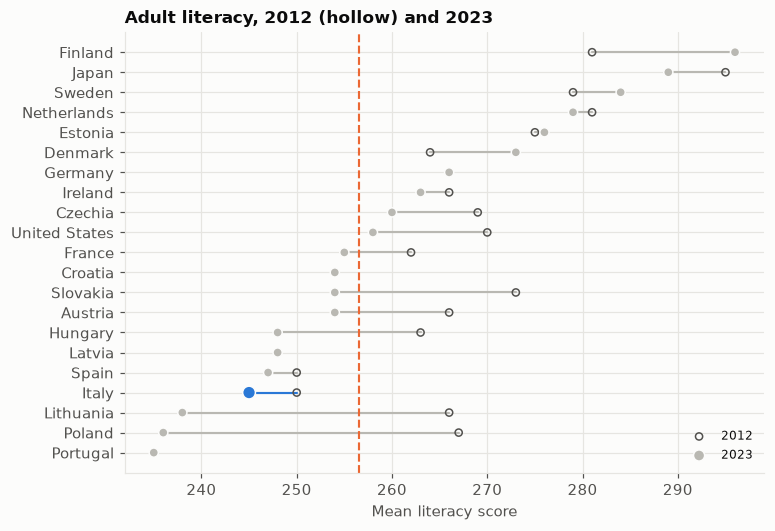

In [7]:
from cifresignificative.core.countries import NAMES
keys = ["literacy", "numeracy", "adaptive_problem_solving", "low_literacy_pct", "literacy_16_24", "literacy_25_34", "literacy_55_65", "literacy_women", "literacy_men",
        "literacy_below_upper_secondary", "literacy_tertiary", "literacy_parents_no_upper_secondary", "literacy_parent_tertiary"]
pl = {k: wide(panel, f"piaac_{k}") for k in keys}
y23 = pl["literacy"].loc[2023, [c for c in pl["literacy"] if c in EU27_ISO3 or c in BENCHMARKS]].dropna().sort_values()
y12 = pl["literacy"].loc[2012].reindex(y23.index)
fig, ax = plt.subplots(figsize=(7.5, 5.2)); yy = np.arange(len(y23))
for i, c in enumerate(y23.index):
    if not np.isnan(y12[c]): ax.plot([y12[c], y23[c]], [i, i], color=PEER_C if c != ITALY else ITALY_C, lw=1.4)
ax.scatter(y12.values, yy, s=22, facecolor="none", edgecolor=INK2, zorder=3, label="2012")
ax.scatter(y23.values, yy, s=[70 if c == ITALY else 36 for c in y23.index], color=[ITALY_C if c == ITALY else PEER_C for c in y23.index], edgecolor=SURFACE, zorder=4, label="2023")
ax.set_yticks(yy, [NAMES.get(c, c) for c in y23.index]); ax.axvline(pl["literacy"].loc[2023].drop(ITALY).median(), color=EU_C, ls="--", lw=1.4)
ax.set_xlabel("Mean literacy score"); ax.set_title("Adult literacy, 2012 (hollow) and 2023"); ax.legend(fontsize=8, loc="lower right"); save(fig, "12_piaac_literacy")
def row_of(w): return {"Italy": w.loc[2023, ITALY], "median others": eu_median_ex_italy(w, 0.5).loc[2023], "rank (1=highest)": "%d/%d" % italy_rank(w, 2023)}
tab = pd.DataFrame({"literacy": row_of(pl["literacy"]), "numeracy": row_of(wide(panel, "piaac_numeracy")), "adaptive problem solving": row_of(pl["adaptive_problem_solving"]), "% at level 1 or below (literacy)": row_of(pl["low_literacy_pct"])}).T
display(tab.round(1))
groups = {"16-24": "literacy_16_24", "25-34": "literacy_25_34", "55-65": "literacy_55_65", "women": "literacy_women", "men": "literacy_men", "below upper secondary": "literacy_below_upper_secondary", "tertiary": "literacy_tertiary",
          "parents: none upper secondary": "literacy_parents_no_upper_secondary", "parent tertiary": "literacy_parent_tertiary"}
g = pd.DataFrame({lab: {"Italy": pl[k].loc[2023, ITALY], "median others": eu_median_ex_italy(pl[k], 0.5).loc[2023], "gap": pl[k].loc[2023, ITALY] - eu_median_ex_italy(pl[k], 0.5).loc[2023]} for lab, k in groups.items()}).T
display(g.round(1))
mob = (pl["literacy_parent_tertiary"] - pl["literacy_parents_no_upper_secondary"]).loc[2023].dropna()
print("Literacy gap between children of tertiary-educated and low-educated parents: Italy %.0f points vs median of others %.0f (rank %d/%d, 1 = largest gap)" % (mob[ITALY], mob.drop(ITALY).median(), mob.rank(ascending=False)[ITALY], len(mob)))
sk = (pl["literacy_tertiary"] - pl["literacy_below_upper_secondary"]).loc[2023].dropna()
print("Tertiary vs below-upper-secondary literacy gap: Italy %.0f vs median %.0f" % (sk[ITALY], sk.drop(ITALY).median()))
chg = (pl["literacy"].loc[2023] - pl["literacy"].loc[2012]).dropna(); print("Change in literacy 2012-2023: Italy %+.0f | median of others %+.0f | countries with data %d" % (chg[ITALY], chg.drop(ITALY).median(), len(chg)))

## Takeaways: adult skills (PIAAC, OECD Education GPS export; 19 EU members, 2023)
- **Italy scores below most participating countries.** Mean literacy 245 (median of the other EU members 254.5; 16th of 19), numeracy 244 (262; 17th) and adaptive problem solving 231 (248.5; 17th). 34.7% of adults are at level 1 or below in literacy (median 26.2%; 4th highest of 19; Germany 22.5%).
- **Not a recent decline relative to peers.** Mean literacy fell by 5 points from 250 in 2012 to 245 in 2023, while the median of the other countries with data fell by 6. The gap is long-standing rather than new.
- **Young Italians catch up only partly.** Scores are 263 for 16-24 year-olds (median 272.5), 253 for 25-34 (268.5; the widest gap, -15.5 points) and 232 for 55-65 (240.5). Younger cohorts score higher than older ones, as elsewhere, but the gap to peers does not close.
- **Graduates are where the shortfall is.** Adults below upper-secondary education score *above* peers (217 vs 207) but tertiary graduates score 271 vs 283.5. A degree adds 54 literacy points over the lowest education level in Italy, against 72 in the median country: low attainment and weaker skills of graduates reinforce each other.
- **Family background matters less than elsewhere, from a lower starting point.** Children of tertiary-educated parents score 272 (median 283); of parents without upper-secondary schooling 233 (median 232.5): the gap by parental education is 39 points against 48 in the median country (14th of 21).
- **Gender:** women 247, men 244, a small female advantage like the median. Caveats: Belgium and the UK are only partly covered, 2012 levels are derived from reported changes, and the 2023 survey's cross-country comparability is stated by the OECD only within its published confidence intervals (not reproduced here).